# WP0.9 — where does the strongly negative self-connection come from? (new analysis)

The learned diagonal is ≈ −1.3 (Fig. 1D/F spike; Supp. 1G cluster), and it sets the learned eigenvalues above the
active modes (WP0.8). Ablations on the Fig. 1 target (a = 0.5, σ = 1.7 s, b = 0), dev settings: noise off, P(0) scale
p ∈ {0.008, 0.8}, the standard RLS step (no extra c, A2), training toward y* (`supplement`, A1), no state reset (A3).

For each: mean self-weight, test correlation, profile (d ≠ 0) correlation with the baseline, and Floquet analysis of
realisation 1 without noise (period, flow multiplier, leading transverse multiplier; `seqnet.analysis.stability`).

**Panels:** A self-weight per ablation · B profiles · C Floquet summary.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from seqnet.figures import Figure, style
from seqnet.experiments import wp0
from seqnet import conventions as cv
from seqnet.analysis.stability import floquet
from seqnet.targets import SequenceSpec
from seqnet.training.rls import pearson

style()
fig = Figure("wp0", "wp0_9_self_connections")
spec = SequenceSpec(amp=0.5, width=1.7, offset=0.0); h0 = spec.h_target(np.array([0.0]))[:, 0]
runs = {k: wp0.get_ablation(k) for k in wp0.ABLATIONS}
runs["final (Fig. 1)"] = wp0.get(0.5, 1.7, 0.0, "final", store_full="all")
names = list(runs)

## Panel A — mean self-weight and performance per ablation

In [2]:
diag = np.array([runs[k].summary["diag_mean"].mean() for k in names]); diag_sd = np.array([runs[k].summary["diag_mean"].std() for k in names])
test = np.array([runs[k].summary["corr"][:, -runs[k].meta["config"]["n_test"]:].mean() for k in names])
base = cv.profile_from_matrix(runs["baseline"].summary["mean_W"])
pc = np.array([pearson(np.delete(cv.profile_from_matrix(runs[k].summary["mean_W"]), 0), np.delete(base, 0)) for k in names])
fig.save("A_summary", names=np.array(names), diag=diag, diag_sd=diag_sd, test=test, profile_corr=pc)

WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/wp0_9_self_connections/A_summary.npz')

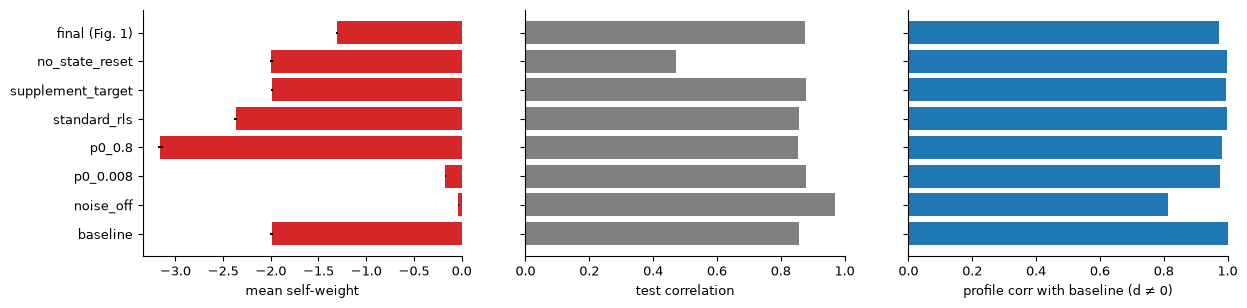

baseline               diag -1.989  test 0.857  profile corr 1.000
noise_off              diag -0.034  test 0.969  profile corr 0.812
p0_0.008               diag -0.169  test 0.879  profile corr 0.978
p0_0.8                 diag -3.159  test 0.854  profile corr 0.983
standard_rls           diag -2.369  test 0.857  profile corr 0.999
supplement_target      diag -1.989  test 0.880  profile corr 0.994
no_state_reset         diag -1.995  test 0.472  profile corr 0.999
final (Fig. 1)         diag -1.308  test 0.876  profile corr 0.973


In [3]:
d = fig.load("A_summary")
F, axs = plt.subplots(1, 3, figsize=(14, 3.2))
y = np.arange(len(names))
axs[0].barh(y, d["diag"], xerr=d["diag_sd"], color="tab:red"); axs[0].set_yticks(y, names); axs[0].set_xlabel("mean self-weight")
axs[1].barh(y, d["test"], color="0.5"); axs[1].set_yticks(y, []); axs[1].set_xlabel("test correlation"); axs[1].set_xlim(0, 1)
axs[2].barh(y, d["profile_corr"], color="tab:blue"); axs[2].set_yticks(y, []); axs[2].set_xlabel("profile corr with baseline (d ≠ 0)"); axs[2].set_xlim(0, 1)
fig.savefig("A_summary", F); plt.show()
for n_, dg, t, p in zip(names, d["diag"], d["test"], d["profile_corr"]): print(f"{n_:22s} diag {dg:+.3f}  test {t:.3f}  profile corr {p:.3f}")

## Panel B — mean-matrix profiles (raw, including d = 0)

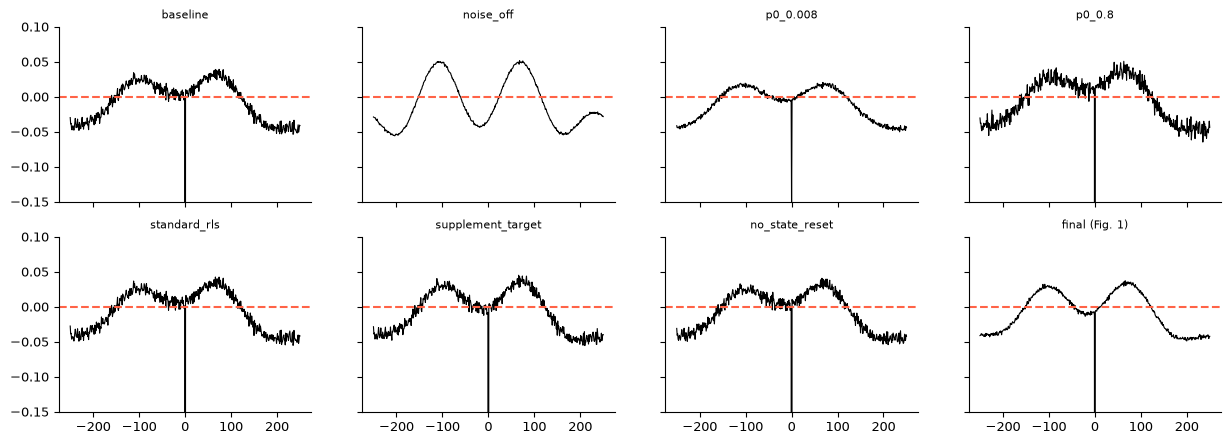

In [4]:
P = {k: cv.centred_profile(cv.profile_from_matrix(runs[k].summary["mean_W"])) for k in names}
fig.save("B_profiles", d=P[names[0]][0], **{f"cp_{i}": P[k][1] for i, k in enumerate(names)})
d = fig.load("B_profiles")
F, axs = plt.subplots(2, 4, figsize=(15, 5), sharex=True, sharey=True)
for ax, (i, k) in zip(axs.flat, enumerate(names)):
    ax.plot(d["d"], d[f"cp_{i}"], "k", lw=0.8); ax.axhline(0, color="tomato", ls="--"); ax.set_title(k, fontsize=8); ax.set_ylim(-0.15, 0.1)
fig.savefig("B_profiles", F); plt.show()

## Panel C — Floquet analysis of realisation 1 (noise-free, frozen weights)

In [5]:
res = {k: floquet(runs[k].W(0), h0, int(round(spec.T / 0.0081))) for k in names}
fig.save("C_floquet", names=np.array(names), kept=np.array([res[k].sequence_kept for k in names]),
         period_s=np.array([res[k].period_steps * 0.0081 for k in names]), closure=np.array([res[k].closure_error for k in names]),
         flow=np.array([abs(res[k].flow_multiplier) for k in names]), transverse=np.array([abs(res[k].leading_transverse[0]) for k in names]))
d = fig.load("C_floquet")
for n_, kp, ps, fl, tr, cl in zip(names, d["kept"], d["period_s"], d["flow"], d["transverse"], d["closure"]):
    print(f"{n_:22s} sequence kept {bool(kp)!s:5s} period {ps:.2f} s  |flow mult| {fl:.4f}  leading transverse {tr:.4f}  closure {cl:.1e}")

baseline               sequence kept True  period 8.71 s  |flow mult| 1.0006  leading transverse 0.0041  closure 5.9e-04
noise_off              sequence kept True  period 8.80 s  |flow mult| 1.0010  leading transverse 0.0082  closure 1.4e-03
p0_0.008               sequence kept True  period 8.72 s  |flow mult| 1.0009  leading transverse 0.0072  closure 1.2e-03
p0_0.8                 sequence kept True  period 8.63 s  |flow mult| 1.0011  leading transverse 0.0032  closure 7.6e-04
standard_rls           sequence kept True  period 8.71 s  |flow mult| 1.0007  leading transverse 0.0038  closure 3.3e-04
supplement_target      sequence kept True  period 8.50 s  |flow mult| 1.0004  leading transverse 0.0037  closure 5.9e-04
no_state_reset         sequence kept True  period 8.45 s  |flow mult| 1.0006  leading transverse 0.0050  closure 3.0e-04
final (Fig. 1)         sequence kept True  period 8.85 s  |flow mult| 1.0007  leading transverse 0.0047  closure 1.2e-03


## Acceptance (findings are reported; spec WP0.9 asks for the mean diagonal per ablation and its effect on stability)

In [6]:
a = fig.load("A_summary"); c = fig.load("C_floquet")
fig.checks([
    {"item": "mean self-weight per ablation", "criterion": "reported", "value": dict(zip(names, np.round(a["diag"], 3))), "passed": None},
    {"item": "noise-free sequence kept and Floquet multipliers", "criterion": "reported",
     "value": {n_: {"kept": bool(k), "period_s": round(float(p), 2), "leading_transverse": round(float(t), 4)} for n_, k, p, t in zip(names, c["kept"], c["period_s"], c["transverse"])}, "passed": None},
    {"item": "T17 on trained networks: flow multiplier ~1 where the sequence is kept", "criterion": "|flow - 1| < 5 * closure + 1e-3",
     "value": c["flow"][c["kept"]], "passed": bool(np.all(np.abs(c["flow"][c["kept"]] - 1) < 5 * c["closure"][c["kept"]] + 1e-3))},
])

[info] mean self-weight per ablation: {'baseline': np.float64(-1.989), 'noise_off': np.float64(-0.034), 'p0_0.008': np.float64(-0.169), 'p0_0.8': np.float64(-3.159), 'standard_rls': np.float64(-2.369), 'supplement_target': np.float64(-1.989), 'no_state_reset': np.float64(-1.995), 'final (Fig. 1)': np.float64(-1.308)}
[info] noise-free sequence kept and Floquet multipliers: {'baseline': {'kept': True, 'period_s': 8.71, 'leading_transverse': 0.0041}, 'noise_off': {'kept': True, 'period_s': 8.8, 'leading_transverse': 0.0082}, 'p0_0.008': {'kept': True, 'period_s': 8.72, 'leading_transverse': 0.0072}, 'p0_0.8': {'kept': True, 'period_s': 8.63, 'leading_transverse': 0.0032}, 'standard_rls': {'kept': True, 'period_s': 8.71, 'leading_transverse': 0.0038}, 'supplement_target': {'kept': True, 'period_s': 8.5, 'leading_transverse': 0.0037}, 'no_state_reset': {'kept': True, 'period_s': 8.45, 'leading_transverse': 0.005}, 'final (Fig. 1)': {'kept': True, 'period_s': 8.85, 'leading_transverse': 0.0

WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/wp0_9_self_connections/acceptance.json')